# Comparative Study of Machine Learning Models for Dari Text Classification

Models compared: Support Vector Machine (SVM), Naive Bayes, and Logistic Regression.

This notebook uses only the labeled `train.csv` dataset. The dataset is split internally into training and testing subsets for evaluation. The purpose is to compare the models based on prediction accuracy and computational speed.

In [1]:
# 1. Import required libraries
import os
import re
import time
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay
)

RANDOM_STATE = 42

# Folder for saving generated figures
os.makedirs('figures', exist_ok=True)

## 2. Load labeled training dataset

The notebook reads only `data/train.csv`, because this is the labeled dataset used for supervised learning and evaluation.

In [2]:
df = pd.read_csv('data/train.csv')

print('Dataset shape:', df.shape)
print('Columns:', df.columns.tolist())
print('\nLabel distribution:')
print(df['label'].value_counts())

df.head()

Dataset shape: (3000, 3)
Columns: ['headline', 'content', 'label']

Label distribution:
label
درست      1689
نادرست    1311
Name: count, dtype: int64


,headline,content,label
0,برداشت نمک از دریاچه‌های شور؛ مقایسه ارومیه و ...,دریاچه ارومیه و دریاچه بزرگ نمک در یوتا با چال...,درست
1,مردود شدن سامانه تاد در رهگیری موشک‌های ایرانی,گزارش‌ها نشان می‌دهد سامانه تاد در اولین استفا...,درست
2,headline,بازدید از محل تخریب خانواده ساداتی ارمکی در نا...,درست
3,تصویر نادرست روزنامه ایران در خبر هواپیمای ساخ...,روزنامه ایران گزارشی با عنوان «هواپیمای ساخت د...,نادرست
4,گزارش آماری از انتشار کتاب در تیرماه ۱۴۰۴,براساس آمارها، در تیرماه سال جاری شش‌هزار و 80...,درست


## 3. Dari text preprocessing

This preprocessing function is designed for Dari/Persian-script text. It normalizes Arabic/Persian character variants, removes invisible characters, URLs, Latin letters, digits, unnecessary punctuation, and common Dari stopwords.

In [3]:
DARI_STOPWORDS = set('''
از به در که و را با برای این آن یک ها های می شده شد است هست بود باشد بودند شدن کند کرد کرده کنند
اگر اما یا تا بر نیز هم هر خود خودم خودت خودش ما شما آنها ایشان او من تو وی
زیرا چون چرا چگونه چه کدام وقتی پس پیش بعد بین بدون درباره مانند مثل توسط طی فقط باید
بسیار بیشتر کمتر همه هیچ دیگر زیر بالا داخل خارج امروز فردا دیروز اکنون سپس همچنان
همچون نسبت مورد برخی چند چنین همان همین البته ولی بلکی مگر آیا ترین تر
'''.split())

CHAR_NORMALIZATION_MAP = {
    'ي': 'ی', 'ى': 'ی', 'ئ': 'ی',
    'ك': 'ک',
    'ة': 'ه', 'ۀ': 'ه',
    'ؤ': 'و',
    'إ': 'ا', 'أ': 'ا', 'آ': 'ا', 'ٱ': 'ا',
    '‌': ' ', '‌': ' ', '‏': ' ', '‎': ' ',
    'ـ': ' '
}

DIACRITICS_PATTERN = re.compile(r'[ًٌٍَُِّْٰ]')


def normalize_dari_text(text):
    # Normalize and clean Dari/Persian-script text.
    if pd.isna(text):
        return ''

    text = str(text)

    for src, target in CHAR_NORMALIZATION_MAP.items():
        text = text.replace(src, target)

    text = DIACRITICS_PATTERN.sub('', text)
    text = re.sub(r'http\S+|www\.\S+', ' ', text)
    text = re.sub(r'[@#]\w+', ' ', text)
    text = re.sub(r'[A-Za-z0-9۰-۹٠-٩]+', ' ', text)
    text = re.sub(r'[^؀-ۿ\s]', ' ', text)
    text = re.sub(r'\s+', ' ', text).strip()

    return text


def remove_dari_stopwords(text):
    tokens = text.split()
    tokens = [token for token in tokens if len(token) >= 2 and token not in DARI_STOPWORDS]
    return ' '.join(tokens)


def preprocess_dari_text(text):
    text = normalize_dari_text(text)
    text = remove_dari_stopwords(text)
    return text

## 4. Combine headline and content

The headline and content fields are combined into one text column. The combined text is then cleaned using the Dari preprocessing function.

In [4]:
df = df.dropna(subset=['label']).copy()
df['headline'] = df['headline'].fillna('')
df['content'] = df['content'].fillna('')

df['raw_text'] = df['headline'] + ' ' + df['content']
df['clean_text'] = df['raw_text'].apply(preprocess_dari_text)

df = df[df['clean_text'].str.len() > 0].copy()

print('Final labeled rows:', len(df))
df[['raw_text', 'clean_text', 'label']].head()

Final labeled rows: 3000


,raw_text,clean_text,label
0,برداشت نمک از دریاچه‌های شور؛ مقایسه ارومیه و ...,برداشت نمک دریاچه شور؛ مقایسه ارومیه یوتا دریا...,درست
1,مردود شدن سامانه تاد در رهگیری موشک‌های ایرانی...,مردود سامانه تاد رهگیری موشک ایرانی گزارش نشان...,درست
2,headline بازدید از محل تخریب خانواده ساداتی ار...,بازدید محل تخریب خانواده ساداتی ارمکی نارمک ته...,درست
3,تصویر نادرست روزنامه ایران در خبر هواپیمای ساخ...,تصویر نادرست روزنامه ایران خبر هواپیمای ساخت ر...,نادرست
4,گزارش آماری از انتشار کتاب در تیرماه ۱۴۰۴ براس...,گزارش اماری انتشار کتاب تیرماه براساس امارها، ...,درست


## 5. Train-test split

The labeled dataset is divided into 80% training data and 20% testing data. Stratification is used to keep the class distribution similar in both subsets.

In [5]:
X = df['clean_text']
y = df['label']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print('Training samples:', len(X_train))
print('Testing samples:', len(X_test))

print('\nTraining label distribution:')
print(y_train.value_counts(normalize=True))

print('\nTesting label distribution:')
print(y_test.value_counts(normalize=True))

Training samples: 2400
Testing samples: 600

Training label distribution:
label
درست      0.562917
نادرست    0.437083
Name: proportion, dtype: float64

Testing label distribution:
label
درست      0.563333
نادرست    0.436667
Name: proportion, dtype: float64


## 6. TF-IDF feature extraction

TF-IDF is fitted only on the training data and then applied to the testing data. This prevents data leakage.

In [6]:
tfidf = TfidfVectorizer(
    tokenizer=str.split,
    token_pattern=None,
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.95,
    sublinear_tf=True
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print('TF-IDF training shape:', X_train_tfidf.shape)
print('TF-IDF testing shape:', X_test_tfidf.shape)

TF-IDF training shape: (2400, 17562)
TF-IDF testing shape: (600, 17562)


## 7. Train and evaluate baseline models

In [7]:
models = {
    'SVM': LinearSVC(random_state=RANDOM_STATE, class_weight='balanced', max_iter=5000),
    'Naive Bayes': MultinomialNB(),
    'Logistic Regression': LogisticRegression(
        random_state=RANDOM_STATE,
        class_weight='balanced',
        solver='liblinear',
        max_iter=3000
    )
}

results = []
predictions = {}

for model_name, model in models.items():
    model.fit(X_train_tfidf, y_train)
    y_pred = model.predict(X_test_tfidf)
    predictions[model_name] = y_pred

    results.append({
        'Model': model_name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred, average='weighted', zero_division=0),
        'Recall': recall_score(y_test, y_pred, average='weighted', zero_division=0),
        'F1-score': f1_score(y_test, y_pred, average='weighted', zero_division=0)
    })

results_df = pd.DataFrame(results).sort_values(by='F1-score', ascending=False)
results_df

,Model,Accuracy,Precision,Recall,F1-score
2,Logistic Regression,0.856667,0.856594,0.856667,0.856153
1,Naive Bayes,0.855000,0.855270,0.855000,0.854254
0,SVM,0.833333,0.833491,0.833333,0.833403


## 8. Detailed classification reports

In [8]:
for model_name, y_pred in predictions.items():
    print('=' * 70)
    print(f'Classification Report - {model_name}')
    print('=' * 70)
    print(classification_report(y_test, y_pred, zero_division=0))

Classification Report - SVM
              precision    recall  f1-score   support

        درست       0.85      0.85      0.85       338
      نادرست       0.81      0.81      0.81       262

    accuracy                           0.83       600
   macro avg       0.83      0.83      0.83       600
weighted avg       0.83      0.83      0.83       600

Classification Report - Naive Bayes
              precision    recall  f1-score   support

        درست       0.85      0.90      0.87       338
      نادرست       0.86      0.80      0.83       262

    accuracy                           0.85       600
   macro avg       0.86      0.85      0.85       600
weighted avg       0.86      0.85      0.85       600

Classification Report - Logistic Regression
              precision    recall  f1-score   support

        درست       0.86      0.89      0.88       338
      نادرست       0.85      0.81      0.83       262

    accuracy                           0.86       600
   macro avg       0

## 9. Confusion matrices

The class labels are displayed in English to make the plots clearer for thesis presentation. Each generated confusion matrix is also saved in the `figures` folder.

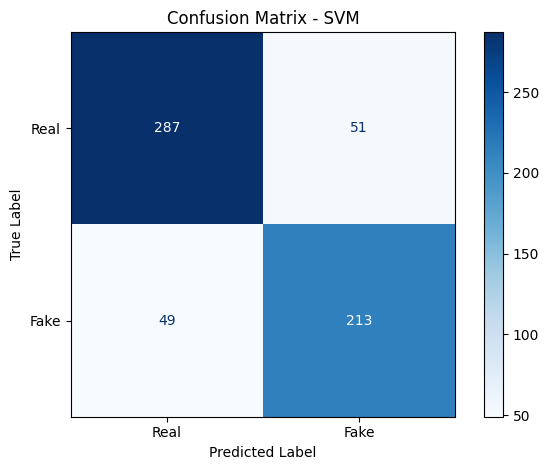

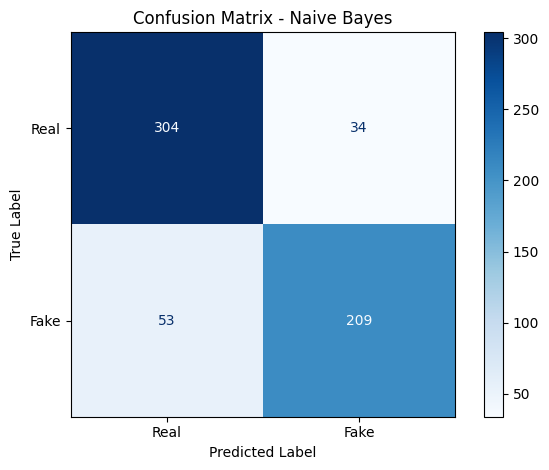

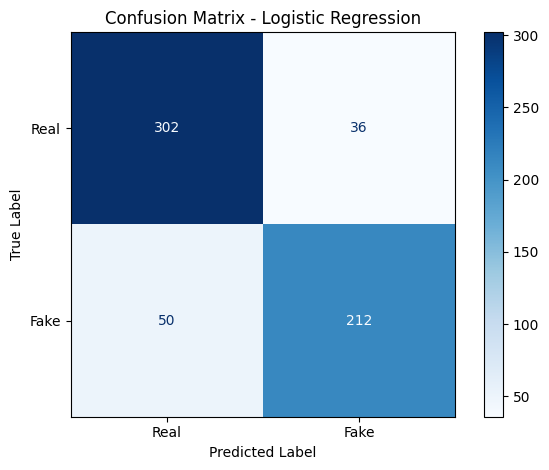

In [9]:
english_map = {
    'درست': 'Real',
    'نادرست': 'Fake'
}

for model_name, y_pred in predictions.items():
    original_labels = models[model_name].classes_
    english_labels = [english_map.get(label, str(label)) for label in original_labels]

    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=original_labels
    )

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=english_labels
    )

    disp.plot(values_format='d', cmap='Blues')
    plt.title(f'Confusion Matrix - {model_name}')
    plt.xlabel('Predicted Label')
    plt.ylabel('True Label')
    plt.tight_layout()
    plt.savefig(f'figures/confusion_matrix_{model_name.replace(" ", "_").lower()}.png', dpi=300, bbox_inches='tight')
    plt.show()

## 10. Cross-validation comparison

Cross-validation gives a more stable comparison of the three models on the labeled dataset.

In [10]:
cv_results = []

for model_name, model in models.items():
    pipeline = Pipeline([
        ('tfidf', TfidfVectorizer(
            tokenizer=str.split,
            token_pattern=None,
            ngram_range=(1, 2),
            min_df=2,
            max_df=0.95,
            sublinear_tf=True
        )),
        ('model', model)
    ])

    scores = cross_val_score(
        pipeline,
        X,
        y,
        cv=5,
        scoring='f1_weighted'
    )

    cv_results.append({
        'Model': model_name,
        'Mean CV F1-score': scores.mean(),
        'Std CV F1-score': scores.std()
    })

cv_results_df = pd.DataFrame(cv_results).sort_values(by='Mean CV F1-score', ascending=False)
cv_results_df

,Model,Mean CV F1-score,Std CV F1-score
2,Logistic Regression,0.841623,0.022433
1,Naive Bayes,0.841251,0.019739
0,SVM,0.828189,0.023178


## 11. Optional hyperparameter tuning

This section improves the comparison by testing several parameter values for each model. It may take more time than baseline training.

In [11]:
param_grids = {
    'SVM': {'model__C': [0.1, 1, 10]},
    'Naive Bayes': {'model__alpha': [0.1, 0.5, 1.0]},
    'Logistic Regression': {'model__C': [0.1, 1, 10]}
}

best_models = {}
tuned_results = []

for model_name, model in models.items():
    pipeline = Pipeline([
        ('tfidf', TfidfVectorizer(
            tokenizer=str.split,
            token_pattern=None,
            ngram_range=(1, 2),
            min_df=2,
            max_df=0.95,
            sublinear_tf=True
        )),
        ('model', model)
    ])

    grid = GridSearchCV(
        pipeline,
        param_grid=param_grids[model_name],
        cv=3,
        scoring='f1_weighted',
        n_jobs=-1
    )

    grid.fit(X_train, y_train)
    y_pred = grid.predict(X_test)
    best_models[model_name] = grid.best_estimator_

    tuned_results.append({
        'Model': model_name,
        'Best Parameters': grid.best_params_,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred, average='weighted', zero_division=0),
        'Recall': recall_score(y_test, y_pred, average='weighted', zero_division=0),
        'F1-score': f1_score(y_test, y_pred, average='weighted', zero_division=0)
    })

tuned_results_df = pd.DataFrame(tuned_results).sort_values(by='F1-score', ascending=False)
tuned_results_df

,Model,Best Parameters,Accuracy,Precision,Recall,F1-score
0,SVM,{'model__C': 0.1},0.856667,0.856594,0.856667,0.856153
2,Logistic Regression,{'model__C': 1},0.856667,0.856594,0.856667,0.856153
1,Naive Bayes,{'model__alpha': 1.0},0.855000,0.855270,0.855000,0.854254


## 12. Final speed and accuracy comparison

This is the main comparative result of the study. It measures accuracy-related metrics and computational speed for each model. Training time shows how long each model takes to learn from the training data, while prediction time shows how fast each model classifies unseen test samples.

In [12]:
comparison_results = []

for model_name, model in models.items():
    start_train = time.time()
    model.fit(X_train_tfidf, y_train)
    end_train = time.time()

    start_predict = time.time()
    y_pred = model.predict(X_test_tfidf)
    end_predict = time.time()

    comparison_results.append({
        'Model': model_name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred, average='weighted', zero_division=0),
        'Recall': recall_score(y_test, y_pred, average='weighted', zero_division=0),
        'F1-Score': f1_score(y_test, y_pred, average='weighted', zero_division=0),
        'Training Time (seconds)': end_train - start_train,
        'Prediction Time (seconds)': end_predict - start_predict
    })

comparison_df = pd.DataFrame(comparison_results)
comparison_df = comparison_df.sort_values(
    by=['Accuracy', 'F1-Score'],
    ascending=False
)

comparison_df

,Model,Accuracy,Precision,Recall,F1-Score,Training Time (seconds),Prediction Time (seconds)
2,Logistic Regression,0.856667,0.856594,0.856667,0.856153,0.030318,0.000997
1,Naive Bayes,0.855000,0.855270,0.855000,0.854254,0.000000,0.000000
0,SVM,0.833333,0.833491,0.833333,0.833403,0.041471,0.000000


## 13. Comparison graphs

The generated graphs are saved in the `figures` folder for use in the thesis document.

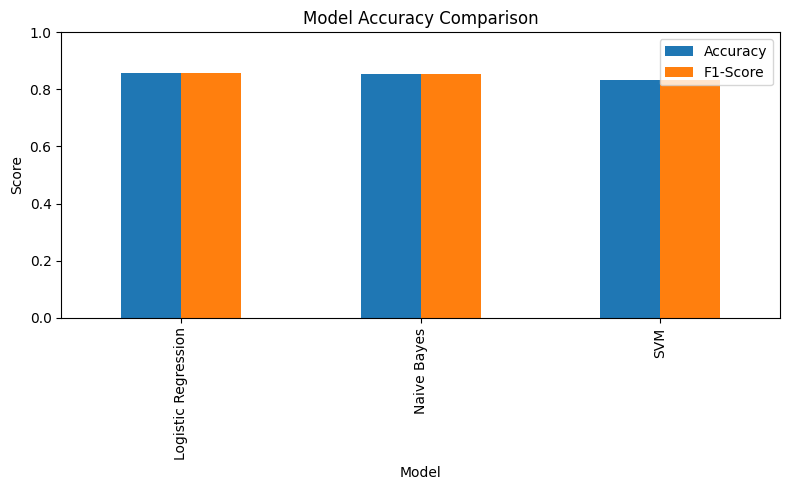

In [13]:
ax = comparison_df.plot(
    x='Model',
    y=['Accuracy', 'F1-Score'],
    kind='bar',
    figsize=(8, 5),
    title='Model Accuracy Comparison'
)

plt.ylabel('Score')
plt.ylim(0, 1)
plt.tight_layout()
plt.savefig('figures/model_accuracy_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

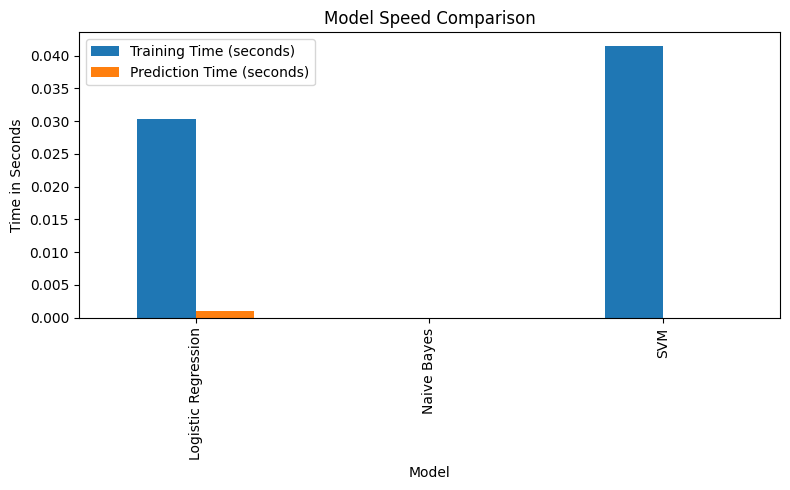

In [14]:
ax = comparison_df.plot(
    x='Model',
    y=['Training Time (seconds)', 'Prediction Time (seconds)'],
    kind='bar',
    figsize=(8, 5),
    title='Model Speed Comparison'
)

plt.ylabel('Time in Seconds')
plt.tight_layout()
plt.savefig('figures/model_speed_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

In [15]:
import os
import joblib

# create folder
os.makedirs("saved_model", exist_ok=True)

# select best model
best_model = models["Logistic Regression"]

# save trained model
joblib.dump(
    best_model,
    "saved_model/logistic_regression_model.pkl"
)

# save TF-IDF vectorizer
joblib.dump(
    tfidf,
    "saved_model/tfidf_vectorizer.pkl"
)

print("Model and vectorizer saved successfully.")
print("Saved folder path:", os.path.abspath("saved_model"))

Model and vectorizer saved successfully.
Saved folder path: c:\Users\Abdul Rahman\Desktop\news_classification\saved_model


## Methodology note for thesis writing

In this study, only the labeled `train.csv` dataset was used for model evaluation. The labeled data was divided into training and testing subsets using an 80/20 stratified split. Text preprocessing was adapted for Dari-script text through character normalization, removal of invisible characters, punctuation, Latin characters, digits, and common stopwords. TF-IDF was used for feature extraction, and the vectorizer was fitted only on the training data to prevent data leakage. Finally, SVM, Naive Bayes, and Logistic Regression were trained and compared using accuracy, precision, recall, F1-score, confusion matrices, cross-validation scores, training time, and prediction time.